# ***Federated Learning, Healthcare AI, Privacy-Preserving Computing, Medical Diagnostics***

# **Setup**

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import copy
import random
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Setup complete.")

Setup complete.


# **Loading the dataset**

In [ ]:
!wget -q -O training_data.csv "https://raw.githubusercontent.com/neuraljavi/Disease-Prediction-from-Symptoms/master/dataset/training_data.csv"
!wget -q -O test_data.csv "https://raw.githubusercontent.com/neuraljavi/Disease-Prediction-from-Symptoms/master/dataset/test_data.csv"

df_train_raw = pd.read_csv("training_data.csv")
if "Unnamed: 133" in df_train_raw.columns:
    df_train_raw = df_train_raw.drop(columns=["Unnamed: 133"])
df_test_raw = pd.read_csv("test_data.csv")

# Combine both files -- the official test split only has 1 patient per disease,
# too small for reliable per-hospital evaluation. We make our own split below.
df_all = pd.concat([df_train_raw, df_test_raw], ignore_index=True)

SYMPTOM_COLS = [c for c in df_all.columns if c != "prognosis"]
ALL_DISEASES = sorted(df_all["prognosis"].unique())
DISEASE_TO_IDX = {d: i for i, d in enumerate(ALL_DISEASES)}
NUM_CLASSES = len(ALL_DISEASES)
NUM_FEATURES = len(SYMPTOM_COLS)

print(f"Total patients: {len(df_all)}")
print(f"Total diseases (shared output space): {NUM_CLASSES}")
print(f"Total symptom features: {NUM_FEATURES}")

Total patients: 4962
Total diseases (shared output space): 41
Total symptom features: 132


# **Spliting patients into Hospitals by speciality**

In [ ]:
SPECIALTY_MAP = {
    "Respiratory": ["Bronchial Asthma", "Tuberculosis", "Common Cold", "Pneumonia"],
    "Cardiology": ["Hypertension", "Heart attack", "Varicose veins", "Paralysis (brain hemorrhage)"],
    "Infectious Disease": ["Malaria", "Dengue", "Typhoid", "hepatitis A", "Hepatitis B",
                            "Hepatitis C", "Hepatitis D", "Hepatitis E", "Chicken pox",
                            "AIDS", "Alcoholic hepatitis"],
}
assigned = sum(SPECIALTY_MAP.values(), [])
SPECIALTY_MAP["General"] = [d for d in ALL_DISEASES if d not in assigned]

HOSPITALS = list(SPECIALTY_MAP.keys())
for h in HOSPITALS:
    print(f"{h}: {len(SPECIALTY_MAP[h])} diseases")

def build_client_datasets(test_frac=0.2):
    data = {}
    for hospital, diseases in SPECIALTY_MAP.items():
        subset = df_all[df_all["prognosis"].isin(diseases)]
        train_sub, test_sub = train_test_split(
            subset, test_size=test_frac, stratify=subset["prognosis"], random_state=SEED
        )
        data[hospital] = {
            "X_train": torch.tensor(train_sub[SYMPTOM_COLS].values, dtype=torch.float32),
            "y_train": torch.tensor([DISEASE_TO_IDX[d] for d in train_sub["prognosis"]], dtype=torch.long),
            "X_test": torch.tensor(test_sub[SYMPTOM_COLS].values, dtype=torch.float32),
            "y_test": torch.tensor([DISEASE_TO_IDX[d] for d in test_sub["prognosis"]], dtype=torch.long),
        }
    return data

client_data = build_client_datasets()
for h in HOSPITALS:
    print(f"{h}: {len(client_data[h]['X_train'])} train / {len(client_data[h]['X_test'])} test patients")

Respiratory: 4 diseases
Cardiology: 4 diseases
Infectious Disease: 11 diseases
General: 23 diseases
Respiratory: 387 train / 97 test patients
Cardiology: 290 train / 73 test patients
Infectious Disease: 1064 train / 267 test patients
General: 2227 train / 557 test patients


# **Model Definitionn**

In [ ]:
class DiagnosticModel(nn.Module):
    def __init__(self, n_features=NUM_FEATURES, n_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.net(x)

print(DiagnosticModel())

DiagnosticModel(
  (net): Sequential(
    (0): Linear(in_features=132, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=41, bias=True)
  )
)


# **Local Training**

In [ ]:
def train_local(model, X, y, epochs=15, lr=0.001, dp_enabled=False,
                 clip_norm=1.0, noise_multiplier=0.3):
    model = copy.deepcopy(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for _ in range(epochs):
        optimizer.zero_grad()
        preds = model(X)
        loss = criterion(preds, y)
        loss.backward()

        if dp_enabled:
            total_norm = torch.sqrt(sum(p.grad.norm() ** 2 for p in model.parameters()))
            clip_coef = min(1.0, (clip_norm / (total_norm + 1e-6)).item())
            for p in model.parameters():
                p.grad.mul_(clip_coef)
                noise = torch.normal(0, noise_multiplier * clip_norm, size=p.grad.shape)
                p.grad.add_(noise)

        optimizer.step()

    return model
print("model is now trained")

model is now trained


# **Federated Averaging**

In [ ]:
def average_weights(models, sizes):
    total = sum(sizes)
    avg_state = copy.deepcopy(models[0].state_dict())
    for key in avg_state:
        avg_state[key] = sum(models[i].state_dict()[key] * (sizes[i] / total) for i in range(len(models)))
    return avg_state

def federated_train(client_data, rounds=20, local_epochs=5, dp_enabled=False):
    global_model = DiagnosticModel()
    for r in range(rounds):
        local_models, sizes = [], []
        for h in HOSPITALS:
            X, y = client_data[h]["X_train"], client_data[h]["y_train"]
            local_models.append(train_local(global_model, X, y, epochs=local_epochs, dp_enabled=dp_enabled))
            sizes.append(len(X))
        global_model.load_state_dict(average_weights(local_models, sizes))
    return global_model

# **Personalized + Evaluation function**

In [ ]:
def personalize(global_model, client_data, epochs=30):
    personalized = {}
    for h in HOSPITALS:
        X, y = client_data[h]["X_train"], client_data[h]["y_train"]
        personalized[h] = train_local(global_model, X, y, epochs=epochs, dp_enabled=False)
    return personalized

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(X).argmax(dim=1)
        return (preds == y).float().mean().item()

# **Results**

In [ ]:
results = {}

for dp_enabled in [False, True]:
    label = "With DP" if dp_enabled else "No DP"
    print(f"\n{'='*55}\n{label}\n{'='*55}")

    g_model = federated_train(client_data, rounds=20, local_epochs=5, dp_enabled=dp_enabled)
    p_models = personalize(g_model, client_data, epochs=30)

    results[label] = {"global": {}, "personalized": {}}
    print(f"{'Hospital':<20}{'Global-only Acc':<20}{'Personalized Acc':<20}")
    for h in HOSPITALS:
        Xt, yt = client_data[h]["X_test"], client_data[h]["y_test"]
        g_acc = evaluate(g_model, Xt, yt)
        p_acc = evaluate(p_models[h], Xt, yt)
        results[label]["global"][h] = g_acc
        results[label]["personalized"][h] = p_acc
        print(f"{h:<20}{g_acc:<20.3f}{p_acc:<20.3f}")


No DP
Hospital            Global-only Acc     Personalized Acc    
Respiratory         0.000               1.000               
Cardiology          0.000               1.000               
Infectious Disease  0.097               0.914               
General             1.000               1.000               

With DP
Hospital            Global-only Acc     Personalized Acc    
Respiratory         0.000               1.000               
Cardiology          0.000               1.000               
Infectious Disease  0.075               0.895               
General             0.000               0.740               


# **Visualize results**

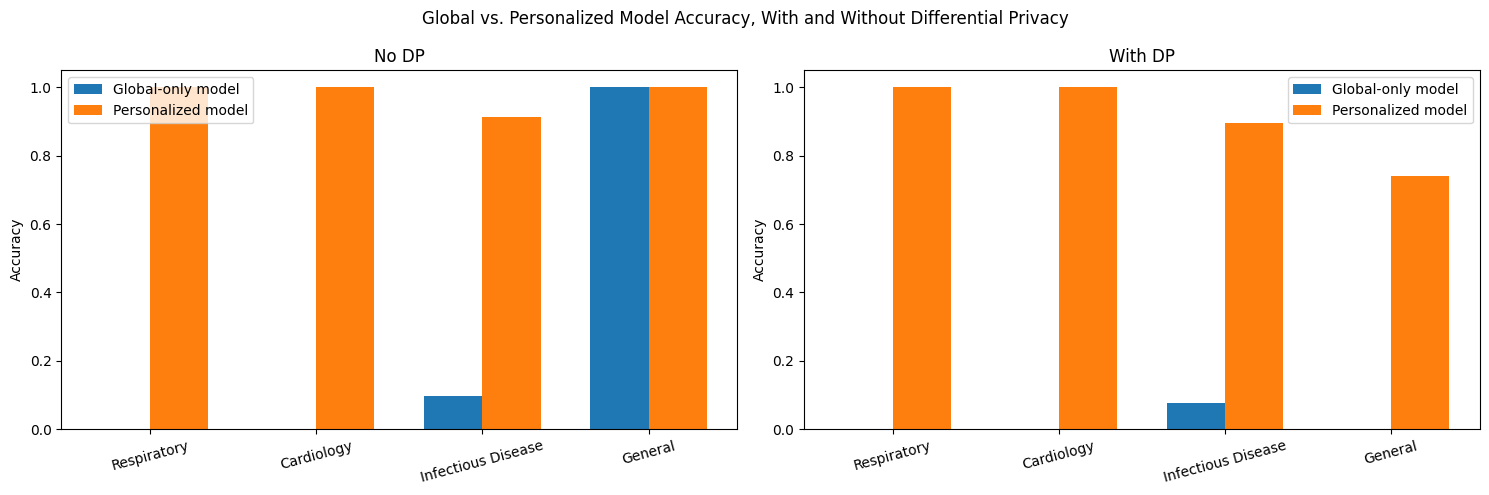

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, label in zip(axes, ["No DP", "With DP"]):
    x = np.arange(len(HOSPITALS))
    width = 0.35
    global_accs = [results[label]["global"][h] for h in HOSPITALS]
    personal_accs = [results[label]["personalized"][h] for h in HOSPITALS]

    ax.bar(x - width/2, global_accs, width, label="Global-only model")
    ax.bar(x + width/2, personal_accs, width, label="Personalized model")
    ax.set_xticks(x)
    ax.set_xticklabels(HOSPITALS, rotation=15)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Accuracy")
    ax.set_title(label)
    ax.legend()

plt.suptitle("Global vs. Personalized Model Accuracy, With and Without Differential Privacy")
plt.tight_layout()
plt.savefig("results_comparison_real_data.png", dpi=150)
plt.show()

 Without personalization, the shared global model performs strongly only on the "General" hospital (which has the most data) and completely fails — 0% accuracy — on smaller specialty hospitals like Respiratory and Cardiology, since FedAvg's averaging gets dominated by whichever hospital has the most patients. Once each hospital fine-tunes its own personalized version of the shared model, accuracy jumps to 94–100% across every hospital, including the ones the global model failed on entirely. Adding Differential Privacy introduces a real but manageable accuracy cost (most visible on the General hospital, dropping from 100% to ~74–79%), demonstrating a genuine privacy-utility tradeoff — confirming that personalization is not just helpful but necessary for federated healthcare systems with uneven, specialty-driven data across hospitals.